# Task 3 · Cleaning Data: US Election 2020 Tweets

**Track:** Data Analytics · Level 1
**Dataset:** *US Election 2020 Tweets* (Kaggle): `hashtag_donaldtrump.csv` and `hashtag_joebiden.csv`
**Tools:** Python, pandas, numpy, matplotlib

**Goal:** turn two raw, messy tweet exports into one clean, analysis-ready dataset, and document every decision.

**How to run:** put the two CSV files in the same folder as this notebook and run all cells. The final cell writes `cleaned_election_tweets.csv`.

> **Why a sample?** Together the two files are about 860 MB (~1.75 million tweets). To keep this notebook fast
> and light on memory, I keep **1 in 5 tweets**, chosen by a rule on the tweet ID (not "the first N rows", which
> would only cover a few days). Because the rule depends only on the ID, a tweet that appears in *both* files is
> either kept in both or dropped from both, so the duplicate-handling step still sees every cross-file duplicate.
> Set `SAMPLE_EVERY = 1` in the first code cell to clean the full data (needs several GB of RAM).

## 1. Load the data and take a first look

In [1]:
import re, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from decimal import Decimal

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

SAMPLE_EVERY = 5           # keep tweets whose numeric ID is divisible by 5 (~20%). Use 1 for all rows.
FILES = {"trump": "hashtag_donaldtrump.csv", "biden": "hashtag_joebiden.csv"}

cleaning_log = []          # every cleaning action is recorded here and shown at the end
def log(step, action, rows_affected):
    cleaning_log.append({"step": step, "action": action, "rows_affected": rows_affected})

In [2]:
def load_sample(path, source_name):
    # Read in chunks, everything as text (dtype=str) so pandas cannot silently change IDs or dates.
    # on_bad_lines="skip" drops the few records whose columns are broken by line breaks inside text fields.
    parts = []
    for chunk in pd.read_csv(path, dtype=str, chunksize=200_000, lineterminator="\n", on_bad_lines="skip"):
        ids = pd.to_numeric(chunk["tweet_id"], errors="coerce")
        keep = chunk[(ids % SAMPLE_EVERY == 0) | ids.isna()]      # rows with an unreadable ID are always kept
        parts.append(keep)
    out = pd.concat(parts, ignore_index=True)
    out["source_file"] = source_name
    return out

raw = pd.concat([load_sample(p, name) for name, p in FILES.items()], ignore_index=True)
print("Raw combined sample (rows, columns):", raw.shape)
print(raw["source_file"].value_counts().to_string())

Raw combined sample (rows, columns): (349509, 22)
source_file
trump    194545
biden    154964


In [3]:
raw.head(3).T

                                                                                0                                                            1  \
created_at                                                    2020-10-15 00:00:02                                          2020-10-15 00:00:26   
tweet_id                                                    1.316529227471237e+18                                       1.3165293286084813e+18   
tweet                 2 hours since last tweet from #Trump! Maybe he is VERY b...  #Trump #PresidentTrump #Trump2020LandslideVictory #Trump...   
likes                                                                         0.0                                                          3.0   
retweet_count                                                                 0.0                                                          5.0   
source                                                              Trumpytweeter                                          T

In [4]:
raw.dtypes.value_counts()

str    22
Name: count, dtype: int64

**Observations**

- The sample has **349,509 rows**: 194,545 from the Trump file and 154,964 from the Biden file, with 22 columns (21 original plus `source_file`, which records which file each row came from).
- Everything is text on purpose. In the first rows you can already see problems: `tweet_id` is `1.316529227471237e+18`, and `likes` is `0.0` instead of `0`.
- A handful of records in the raw files are broken by line breaks inside text fields (about 390 in the Trump file and 300 in the Biden file, roughly 0.04%). `on_bad_lines="skip"` drops them; this is too few to matter.

## 2. Data quality report (before cleaning)

In [5]:
# Which datatype SHOULD each column have? Used to score "dtype accuracy" before and after cleaning.
EXPECTED = {
    "created_at": "datetime", "tweet_id": "id", "tweet": "text", "likes": "int", "retweet_count": "int",
    "source": "text", "user_id": "id", "user_name": "text", "user_screen_name": "text",
    "user_description": "text", "user_join_date": "datetime", "user_followers_count": "int",
    "user_location": "text", "lat": "float", "long": "float", "city": "text", "country": "text",
    "continent": "text", "state": "text", "state_code": "text", "collected_at": "datetime",
}
ORIGINAL_COLS = list(EXPECTED)

def dtype_ok(series, expected):
    t = pd.api.types
    if expected == "datetime": return t.is_datetime64_any_dtype(series)
    if expected == "int":      return t.is_integer_dtype(series)
    if expected == "float":    return t.is_float_dtype(series)
    if expected == "id":       # text that is plain digits only (no scientific notation, no ".0")
        return t.is_string_dtype(series) and series.dropna().astype(str).str.fullmatch(r"\d+").all()
    return t.is_string_dtype(series) or isinstance(series.dtype, pd.CategoricalDtype)

def dtype_report(d):
    ok = {c: dtype_ok(d[c], EXPECTED[c]) for c in ORIGINAL_COLS}
    return ok

def duplicate_tweets(d, id_col="tweet_id"):
    # A duplicate = same tweet_id AND same tweet text as an earlier row
    return int(d.duplicated(subset=[id_col, "tweet"]).sum())

before_ok = dtype_report(raw)
print(f"Columns with the correct datatype: {sum(before_ok.values())} of {len(before_ok)}")
print("Columns with the WRONG datatype:", [c for c, ok in before_ok.items() if not ok])

Columns with the correct datatype: 11 of 21
Columns with the WRONG datatype: ['created_at', 'tweet_id', 'likes', 'retweet_count', 'user_id', 'user_join_date', 'user_followers_count', 'lat', 'long', 'collected_at']


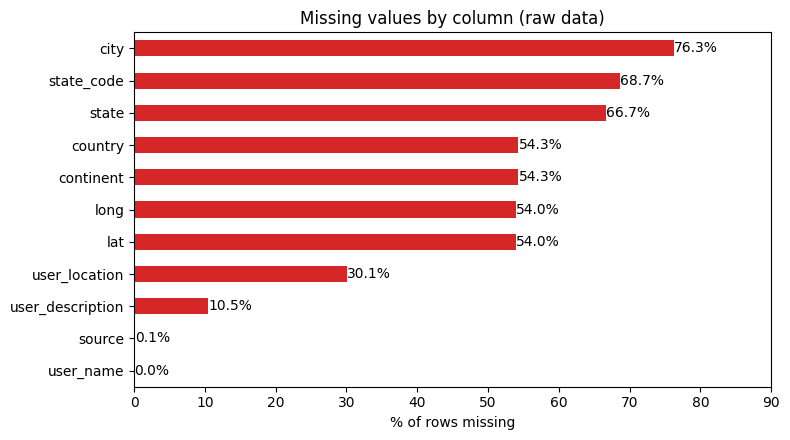

                  null_count  null_%
city                  266664    76.3
state_code            240283    68.7
state                 233014    66.7
country               189697    54.3
continent             189684    54.3
long                  188750    54.0
lat                   188750    54.0
user_location         105331    30.1
user_description       36707    10.5
source                   308     0.1
user_name                  5     0.0

In [6]:
# 1) Missing values
nulls = raw[ORIGINAL_COLS].isna().sum().to_frame("null_count")
nulls["null_%"] = (nulls["null_count"] / len(raw) * 100).round(1)
nulls = nulls[nulls["null_count"] > 0].sort_values("null_%", ascending=False)

ax = nulls["null_%"].sort_values().plot.barh(figsize=(8, 4.5), color="tab:red")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_xlabel("% of rows missing"); ax.set_title("Missing values by column (raw data)")
ax.set_xlim(0, 90)
plt.tight_layout(); plt.show()
nulls

In [7]:
# 2) Duplicates
print("Fully identical rows:", int(raw.drop(columns="source_file").duplicated().sum()))
print("Rows repeating an earlier (tweet_id, tweet) pair:", duplicate_tweets(raw))

# 3) Format problems in the ID columns
for c in ["tweet_id", "user_id"]:
    sci = raw[c].str.contains("e", case=False).mean()
    dot = raw[c].str.fullmatch(r"\d+\.0").mean()
    print(f"{c}: {sci:.1%} in scientific notation (e.g. {raw.loc[raw[c].str.contains('e', case=False), c].iloc[0]}), {dot:.1%} like '12345.0'")

# 4) Numbers stored as text
print("\nlikes sample:", raw["likes"].head(3).tolist(), "| followers sample:", raw["user_followers_count"].head(3).tolist())

Fully identical rows: 0
Rows repeating an earlier (tweet_id, tweet) pair: 45106
tweet_id: 100.0% in scientific notation (e.g. 1.316529227471237e+18), 0.0% like '12345.0'
user_id: 40.7% in scientific notation (e.g. 8.28355589206057e+17), 59.3% like '12345.0'

likes sample: ['0.0', '3.0', '0.0'] | followers sample: ['32.0', '496.0', '6402.0']


In [8]:
# 5) Value-range anomalies and inconsistent labels
lat = pd.to_numeric(raw["lat"]); lon = pd.to_numeric(raw["long"])
print("Latitude range:", lat.min(), "to", lat.max(), "| rows with lat exactly 90 (the North Pole):", int((lat == 90).sum()))
print("Rows with coordinates but NO country:", int((lat.notna() & raw["country"].isna()).sum()))
print("\nMost common 'user_location' for those rows:")
print(raw.loc[lat.notna() & raw["country"].isna(), "user_location"].value_counts().head(6).to_string())

print("\nCountry labels that mean the same place:")
print(raw["country"].value_counts()[["United States of America", "United States", "The Netherlands", "Netherlands", "The Bahamas", "Bahamas"]].to_string())

print("\nDistinct 'source' (app) values:", raw["source"].nunique())
print("Tweets containing HTML entities like &amp; or &gt;:", f'{raw["tweet"].str.contains("&amp;|&gt;|&lt;").mean():.1%}')
ws_pattern = r"\s{2,}|\n"
print("Tweets containing line breaks or repeated spaces:", f'{raw["tweet"].str.contains(ws_pattern).mean():.1%}')

Latitude range: -79.4063075 to 90.0 | rows with lat exactly 90 (the North Pole): 113
Rows with coordinates but NO country: 947

Most common 'user_location' for those rows:
user_location
Europe                            346
North America                     138
North Pole                        105
#PERÚ / EUROPA / #ASIA / LatAm     71
Europa                             69
North America                      32

Country labels that mean the same place:
country
United States of America    66718
United States               12356
The Netherlands              1941
Netherlands                  1079
The Bahamas                    11
Bahamas                         6

Distinct 'source' (app) values: 620
Tweets containing HTML entities like &amp; or &gt;: 6.0%
Tweets containing line breaks or repeated spaces: 51.8%


**Observations: the data quality report**

- **Missing values:** 11 of 21 columns have gaps. The location columns are the emptiest: `city` 76.3%, `state_code` 68.7%, `state` 66.7%, `country` and `continent` 54.3%, `lat`/`long` 54.0%. `user_location` is missing in 30.1% of rows, `user_description` in 10.5%, `source` in 0.1% (308 rows) and `user_name` in 5 rows.
- **Duplicates:** there are **0 fully identical rows**, yet **45,106 rows (12.9%)** repeat an earlier tweet. They are not identical because each copy has a different `collected_at` time and often different like/follower counts, so a plain `drop_duplicates()` would have found nothing.
- **ID format:** `tweet_id` is in scientific notation in **100%** of rows. `user_id` is a mix: 40.7% scientific notation and 59.3% in the form `103083214.0`.
- **Numbers as text:** counts are stored like `0.0` and `496.0`.
- **Suspicious coordinates:** **947 rows** have coordinates but no country. Their `user_location` is a vague place such as `Europe`, `North America` or `North Pole`, and 113 rows sit at exactly latitude 90 (the North Pole), so these are not real city locations.
- **Inconsistent labels:** the same country appears under different names, e.g. `United States of America` (66,718) and `United States` (12,356); `The Netherlands` (1,941) and `Netherlands` (1,079).
- **Text noise:** there are 620 different values in `source`; 6.0% of tweets contain HTML codes such as `&amp;`; and 51.8% contain line breaks or repeated spaces.
- **Datatypes:** only **11 of 21 columns** have the right type, and the 10 wrong ones are the IDs, dates, counts and coordinates.

In [9]:
# Save the "before" numbers now, for the before-vs-after table at the end
before = {
    "Rows": len(raw),
    "Total null cells": int(raw[ORIGINAL_COLS].isna().sum().sum()),
    "Columns with nulls": int((raw[ORIGINAL_COLS].isna().sum() > 0).sum()),
    "Duplicate tweets (same ID + text)": duplicate_tweets(raw),
    "ID values in scientific notation / '.0' form": int(
        raw["tweet_id"].str.contains("e", case=False).sum()
        + raw["user_id"].str.contains(r"e|\.", case=False).sum()),
    "Distinct country labels": raw["country"].nunique(),
    "Coordinates with no real place (no country)": int((lat.notna() & raw["country"].isna()).sum()),
    "Columns with correct dtype (of 21)": sum(before_ok.values()),
    "Dtype accuracy (%)": round(sum(before_ok.values()) / len(before_ok) * 100, 1),
}

## 3. Cleaning step 1: fix IDs and basic data types

**Problem.** Everything was read as text. Worse, the source files stored IDs in scientific notation
(`1.3252266375925555e+18`), and `user_id` is a mix of that and `103083214.0`. Excel or a float conversion
rounded these numbers before the file was published, so **the last few digits of the IDs are already lost** and
cannot be recovered.

**Decision.** Convert every ID to a plain digit string using `Decimal` (no further rounding), keep IDs as
**strings** (never floats), and use them only as keys to identify tweets and users, not to look tweets up on Twitter.
Dates become `datetime`; counts become integers; coordinates become floats.

In [10]:
df = raw.copy()

def plain_digits(value):
    # '1.3252266375925555e+18' -> '1325226637592555500', '103083214.0' -> '103083214'
    if pd.isna(value):
        return np.nan
    try:
        return str(int(Decimal(value)))
    except Exception:
        return np.nan

for c in ["tweet_id", "user_id"]:
    df[c] = df[c].map(plain_digits)

for c in ["created_at", "user_join_date", "collected_at"]:
    df[c] = pd.to_datetime(df[c], format="ISO8601", errors="coerce")

for c in ["likes", "retweet_count", "user_followers_count"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

for c in ["lat", "long"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

log("1. Types", "tweet_id / user_id converted from scientific notation to plain digit strings", len(df))
log("1. Types", "created_at, user_join_date, collected_at converted to datetime", len(df))
log("1. Types", "likes, retweet_count, user_followers_count converted to numbers; lat/long to float", len(df))

# Did the conversions introduce any new missing values (unreadable entries)?
print("Unreadable IDs / dates / counts after conversion:")
print(df[["tweet_id", "user_id", "created_at", "user_join_date", "collected_at",
          "likes", "retweet_count", "user_followers_count"]].isna().sum().to_string())
print("\nSample IDs:", df["tweet_id"].head(2).tolist())
print("Date range of tweets:", df["created_at"].min(), "to", df["created_at"].max())

Unreadable IDs / dates / counts after conversion:
tweet_id                0
user_id                 0
created_at              0
user_join_date          0
collected_at            0
likes                   0
retweet_count           0
user_followers_count    0

Sample IDs: ['1316529227471237000', '1316529328608481300']
Date range of tweets: 2020-10-15 00:00:02 to 2020-11-08 23:59:57


In [11]:
# Logical checks on the dates
print("Users who 'joined' after they tweeted:", int((df["user_join_date"] > df["created_at"]).sum()))
print("Tweets created after they were collected:", int((df["created_at"] > df["collected_at"]).sum()))

# Counts must not be negative, and should be whole numbers
for c in ["likes", "retweet_count", "user_followers_count"]:
    print(f"{c}: min={df[c].min():.0f}, any negative={bool((df[c] < 0).any())}, any non-whole={bool((df[c] % 1 != 0).any())}")
df[["likes", "retweet_count", "user_followers_count"]] = df[["likes", "retweet_count", "user_followers_count"]].astype("int64")

Users who 'joined' after they tweeted: 0
Tweets created after they were collected: 0
likes: min=0, any negative=False, any non-whole=False
retweet_count: min=0, any negative=False, any non-whole=False
user_followers_count: min=0, any negative=False, any non-whole=False


**Observations**

- The conversions introduced **no new missing values**: all IDs, dates and counts were readable.
- The data covers **15 Oct to 8 Nov 2020**, matching the election period.
- The sample ID `1316529227471237000` ends in zeros. That confirms the source file rounded the IDs, so only about the first 16 digits are reliable. IDs are therefore fine as keys, but they will not match real Twitter IDs.
- Logical checks pass: no user joined after tweeting, no tweet was created after it was collected, and the counts are whole numbers with no negatives, so converting them to integers loses nothing.

## 4. Cleaning step 2: remove duplicates

**Problem.** No two rows are *completely* identical, because every copy carries a different `collected_at`
time (and often slightly different like and follower counts). So the duplicates are **the same tweet collected more than once**, in two ways:

1. **Within a file**: the collector picked the same tweet up in two separate scraping runs.
2. **Across files**: a tweet mentioning *both* hashtags is in both the Trump and the Biden file.

**Decisions.**
- A tweet is identified by **`tweet_id` + the tweet text**, not by ID alone. The IDs were rounded in the source file (step 1), so
  different tweets can end up with the same rounded ID. Checking the text as well stops us from deleting genuinely different tweets.
- Before dropping, I record **which hashtag file(s)** each tweet came from (`mentions_trump`, `mentions_biden`), so no information is lost.
- Of each group of copies, I keep the **most recently collected** one, as it has the most up-to-date likes and follower counts.

In [12]:
rows_before = len(df)

# 1) How many different tweets share a rounded ID? (these must NOT be merged)
texts_per_id = df.groupby("tweet_id")["tweet"].nunique()
print("Tweet IDs shared by DIFFERENT tweets (rounding collisions, kept apart):", int((texts_per_id > 1).sum()))

# 2) Remember which hashtag file(s) each tweet appeared in
key = ["tweet_id", "tweet"]
files_per_tweet = df.groupby(key, dropna=False)["source_file"].agg(set)
mentions = pd.DataFrame({
    "mentions_trump": files_per_tweet.map(lambda s: "trump" in s),
    "mentions_biden": files_per_tweet.map(lambda s: "biden" in s),
}).reset_index()

# 3) Count the duplicates by kind, before removing
dup_mask = df.duplicated(subset=key, keep="first")
in_both = int((mentions["mentions_trump"] & mentions["mentions_biden"]).sum())
within_file = int(df.duplicated(subset=key + ["source_file"]).sum())
print("Duplicate rows found:", int(dup_mask.sum()))
print("  repeated collections of a tweet inside ONE file:", within_file)
print("  extra copies caused by a tweet being in BOTH files:", int(dup_mask.sum()) - within_file)
print("  distinct tweets that appear in BOTH hashtag files:", in_both)

# 4) Keep the most recently collected copy of each tweet
df = (df.sort_values("collected_at")
        .drop_duplicates(subset=key, keep="last")
        .merge(mentions, on=key, how="left")
        .drop(columns="source_file")
        .sort_values("created_at")
        .reset_index(drop=True))

removed = rows_before - len(df)
log("2. Duplicates", "removed repeated copies of the same tweet (kept the latest collected_at)", removed)
log("2. Duplicates", "added mentions_trump / mentions_biden flags from the two source files", len(df))

print(f"\nRows before: {rows_before:,} | removed: {removed:,} | rows after: {len(df):,}")
print("Remaining duplicate tweets:", duplicate_tweets(df))
print("\nTweets by hashtag:")
print(df[["mentions_trump", "mentions_biden"]].value_counts().rename("tweets").to_string())

Tweet IDs shared by DIFFERENT tweets (rounding collisions, kept apart): 12
Duplicate rows found: 45106
  repeated collections of a tweet inside ONE file: 639
  extra copies caused by a tweet being in BOTH files: 44467
  distinct tweets that appear in BOTH hashtag files: 44467

Rows before: 349,509 | removed: 45,106 | rows after: 304,403
Remaining duplicate tweets: 0

Tweets by hashtag:
mentions_trump  mentions_biden
True            False             149817
False           True              110119
True            True               44467


**Observations**

- **45,106 rows (12.9%) were removed**: 44,467 were tweets that mention both hashtags and so appear in both files, and 639 were repeated collections of the same tweet inside a single file.
- **12 tweet IDs were shared by different tweets** because of the rounding. Matching on ID alone would have deleted 12 genuine tweets; matching on ID plus text kept them.
- The `mentions_trump` and `mentions_biden` flags keep the information that the removed copies carried. Of the 304,403 unique tweets, **149,817 mention only Trump, 110,119 only Biden, and 44,467 (14.6%) both**.
- No duplicates remain.

## 5. Cleaning step 3: standardise inconsistent text

| Column | Problem | Decision |
|---|---|---|
| `country` | The same country has several labels (`United States` / `United States of America`, `The Netherlands` / `Netherlands`, ...) | Map each variant to one label |
| `tweet`, `user_description` | HTML codes such as `&amp;` and `&gt;`; line breaks and repeated spaces | Decode HTML codes, collapse whitespace to a single space |
| `user_name`, `user_screen_name`, `user_location` | Possible stray spaces | Strip leading and trailing spaces |
| `source` | Over 600 different apps, most used by only a handful of tweets | Keep the original column, add `source_group` with the top 8 apps and `Other` |

I deliberately **do not** try to standardise `user_location`: it is free text typed by users ("Los Angeles, CA", "LA", "california") and rewriting it with rules would be guesswork. The geocoded `country`, `state` and `city` columns already provide the structured version.

In [13]:
# --- country labels
country_map = {
    "United States of America": "United States",
    "The Netherlands": "Netherlands",
    "The Bahamas": "Bahamas",
    "Congo-Brazzaville": "Republic of the Congo",
}
countries_before = df["country"].nunique()
changed = int(df["country"].isin(country_map).sum())
df["country"] = df["country"].replace(country_map)
print(f"Country labels: {countries_before} -> {df['country'].nunique()} ({changed:,} rows relabelled)")
log("3. Standardise", "merged duplicate country labels (e.g. 'United States of America' -> 'United States')", changed)

# --- text columns
def tidy_text(s):
    s = s.map(lambda x: html.unescape(x) if isinstance(x, str) else x)       # &amp; -> &
    return s.str.replace(r"\s+", " ", regex=True).str.strip()             # collapse spaces/newlines

for c in ["tweet", "user_description"]:
    before_text = df[c].copy()
    df[c] = tidy_text(df[c])
    n = int((before_text.fillna("") != df[c].fillna("")).sum())
    print(f"{c}: {n:,} rows changed")
    log("3. Standardise", f"{c}: decoded HTML entities, collapsed whitespace", n)

for c in ["user_name", "user_screen_name", "user_location", "source", "city", "state", "state_code"]:
    stripped = df[c].str.strip()
    n = int((stripped.fillna("") != df[c].fillna("")).sum())
    df[c] = stripped
    log("3. Standardise", f"{c}: stripped leading/trailing spaces", n)

# --- source grouping
top_sources = df["source"].value_counts().head(8).index
df["source_group"] = df["source"].where(df["source"].isin(top_sources), "Other")
df.loc[df["source"].isna(), "source_group"] = np.nan
print("\nsource_group:")
print(df["source_group"].value_counts(dropna=False).to_string())
log("3. Standardise", "added source_group (top 8 apps + Other)", len(df))

Country labels: 177 -> 173 (62,149 rows relabelled)
tweet: 161,093 rows changed
user_description: 70,861 rows changed

source_group:
source_group
Twitter Web App        96406
Twitter for iPhone     92567
Twitter for Android    85192
Twitter for iPad       11404
Other                   9863
TweetDeck               4700
Instagram               1925
Hootsuite Inc.          1374
Buffer                   787
NaN                      185


**Observations**

- **Country labels went from 177 to 173**: four pairs were merged, and 62,149 rows were relabelled (mostly `United States of America` to `United States`).
- **161,093 tweets (about 53%) were changed** by decoding HTML codes and collapsing whitespace, and 70,861 user descriptions. This matters because line breaks and `&amp;` would otherwise distort any later text analysis.
- Stray spaces were found in `user_location` (11,439 rows), `user_name` (61) and `source` (60); the other columns were already tidy.
- `source_group` shrinks 620 apps down to 9 groups. **Three apps (Web App, iPhone, Android) account for about 90% of tweets**, and `Other` is only 3.2%.

## 6. Cleaning step 4: missing data

I decide for **each column** separately, based on *why* the value is missing.

| Column(s) | Why missing | Strategy | Justification |
|---|---|---|---|
| `tweet_id`, `tweet`, `created_at`, `user_id` | Would mean a broken record | **Delete the row** if missing | A tweet with no text, ID or time is unusable (none found) |
| `lat`, `long` | User gave no usable location | **Leave empty** | Filling with a mean or median would place users in the middle of the Atlantic. Also, some rows have coordinates but **no country** (947 in the raw sample, 818 after de-duplication): these are vague places such as `Europe` or `North Pole`, so I blank those coordinates too |
| `city`, `state`, `state_code`, `country`, `continent` | Location not shared or not geocodable | **Fill with `"Unknown"`** | A real, countable group ("we don't know"), so these rows stay in every group-by; no guessing |
| `user_location`, `user_name` | User left the profile field empty (5 rows have no name) | **Fill with `"Unknown"`** | Same reasoning |
| `user_description` | User has no bio | **Fill with empty text `""`** | "No bio" is a genuine value, not missing information |
| `source`, `source_group` | App not recorded (very few rows) | **Fill with `"Unknown"`** | Keeps the rows; the share is tiny |
| `likes`, `retweet_count`, `user_followers_count` | None missing | no action | Mean/median imputation would only apply if there were gaps |

I add a **`has_geo`** column (True when usable coordinates remain) so analysts can still filter to located tweets.

In [14]:
rows_before = len(df)

# 1) Delete rows missing a critical field
critical = ["tweet_id", "tweet", "created_at", "user_id"]
df = df.dropna(subset=critical).reset_index(drop=True)
print("Rows deleted for missing critical fields:", rows_before - len(df))
log("4. Missing", "deleted rows missing tweet_id / tweet / created_at / user_id", rows_before - len(df))

# 2) Coordinates that point at a vague region, not a real place (coordinates present, country missing)
vague = df["lat"].notna() & df["country"].isna()
print("Vague coordinates blanked:", int(vague.sum()))
df.loc[vague, ["lat", "long"]] = np.nan
log("4. Missing", "blanked lat/long that had no country (e.g. 'Europe', 'North Pole')", int(vague.sum()))

# 3) Flag usable geo information
df["has_geo"] = df["lat"].notna()

# 4) Fill categorical / text columns
fill_unknown = ["city", "state", "state_code", "country", "continent", "user_location", "user_name", "source", "source_group"]
for c in fill_unknown:
    n = int(df[c].isna().sum())
    df[c] = df[c].fillna("Unknown")
    log("4. Missing", f"{c}: filled {n:,} missing values with 'Unknown'", n)

n = int(df["user_description"].isna().sum())
df["user_description"] = df["user_description"].fillna("")
log("4. Missing", "user_description: filled missing with empty text", n)

print("\nNulls left in the data:")
remaining = df.isna().sum()
print(remaining[remaining > 0].to_string() if remaining.sum() else "none in text columns; only lat/long remain empty on purpose")
print("\nRows with usable coordinates:", f"{df['has_geo'].mean():.1%}")

Rows deleted for missing critical fields: 0
Vague coordinates blanked: 818

Nulls left in the data:
lat     165450
long    165450

Rows with usable coordinates: 45.6%


**Observations**

- **No rows had to be deleted**: every tweet has an ID, text, time and user.
- **818 coordinates were blanked** because they pointed at a vague region rather than a real place (947 in the raw data before duplicates were removed).
- After cleaning, the **only empty cells left are `lat` and `long`** (165,450 rows), which is deliberate. **45.6% of tweets have usable coordinates**, and the `has_geo` flag marks them.
- The location text columns now contain `"Unknown"` instead of blanks, e.g. 54.4% of tweets have an unknown country and 76.5% an unknown city. This tells an analyst honestly how much of the data cannot be mapped.

## 7. Cleaning step 5: outliers

I test the three engagement columns with both methods from the checklist:

- **IQR rule:** a value above `Q3 + 1.5 × IQR` is an outlier.
- **Z-score:** a value more than 3 standard deviations from the mean is an outlier.

Coordinates are checked separately with a **valid-range test** (latitude -90 to 90, longitude -180 to 180).

In [15]:
def outlier_table(d, cols):
    rows = []
    for c in cols:
        x = d[c]
        q1, q3 = x.quantile([0.25, 0.75])
        fence = q3 + 1.5 * (q3 - q1)
        z = (x - x.mean()) / x.std()
        xl = np.log1p(x); zl = (xl - xl.mean()) / xl.std()
        rows.append({
            "column": c, "median": x.median(), "99th pct": x.quantile(0.99), "max": x.max(),
            "IQR upper fence": fence, "IQR outliers": int((x > fence).sum()),
            "IQR outliers %": round((x > fence).mean() * 100, 1),
            "Z>3 outliers": int((z > 3).sum()), "Z>3 %": round((z > 3).mean() * 100, 2),
            "Z>3 on log1p": int((zl > 3).sum()),
        })
    return pd.DataFrame(rows).set_index("column")

eng_cols = ["likes", "retweet_count", "user_followers_count"]
outlier_table(df, eng_cols).T

column               likes  retweet_count  user_followers_count
median                0.00           0.00                430.00
99th pct            105.98          24.00             324346.26
max              126772.00       20615.00           82417099.00
IQR upper fence       5.00           0.00               4931.00
IQR outliers      30365.00       59179.00              41777.00
IQR outliers %       10.00          19.40                 13.70
Z>3 outliers        299.00         404.00                993.00
Z>3 %                 0.10           0.13                  0.33
Z>3 on log1p       7099.00        7198.00               1568.00

Top 5 accounts by followers in this sample:
user_screen_name  user_followers_count
        ladygaga              82417099
           CNNEE              19154807
        detikcom              16297110
            ndtv              13940738
    CGTNOfficial              13765115

Most-liked tweet has 126,772 likes

Coordinates outside the valid range: 0


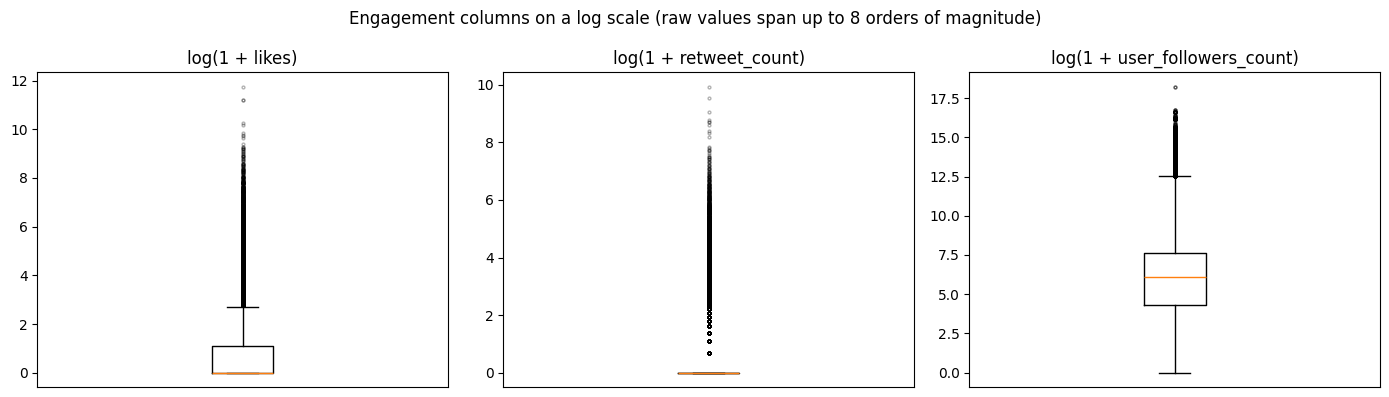

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, eng_cols):
    ax.boxplot(np.log1p(df[c]), vert=True, showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_title(f"log(1 + {c})"); ax.set_xticks([])
plt.suptitle("Engagement columns on a log scale (raw values span up to 8 orders of magnitude)")
plt.tight_layout(); plt.show()

print("Top 5 accounts by followers in this sample:")
print(df.sort_values("user_followers_count", ascending=False).drop_duplicates("user_screen_name")
        .head(5)[["user_screen_name", "user_followers_count"]].to_string(index=False))
print("\nMost-liked tweet has", f"{df['likes'].max():,}", "likes")

# Valid-range check for coordinates
bad_geo = ~df["lat"].between(-90, 90) & df["lat"].notna() | ~df["long"].between(-180, 180) & df["long"].notna()
print("\nCoordinates outside the valid range:", int(bad_geo.sum()))

In [17]:
# Decision: RETAIN all engagement outliers; add log-scaled copies for analysis/modelling
for c in eng_cols:
    df[f"{c}_log1p"] = np.log1p(df[c]).round(4)
log("5. Outliers", "kept all engagement outliers (real viral tweets / large accounts); added *_log1p columns", len(df))
log("5. Outliers", "coordinates checked against valid ranges: none removed", 0)
df[[f"{c}_log1p" for c in eng_cols]].describe().round(2)

       likes_log1p  retweet_count_log1p  user_followers_count_log1p
count    304403.00            304403.00                   304403.00
mean          0.64                 0.25                        5.99
std           1.01                 0.65                        2.53
min           0.00                 0.00                        0.00
25%           0.00                 0.00                        4.34
50%           0.00                 0.00                        6.07
75%           1.10                 0.00                        7.61
max          11.75                 9.93                       18.23

**Observations**

- **The IQR rule is a poor fit here.** These counts are heavily zero-inflated: the median `likes` and `retweet_count` are both 0. For retweets, the upper fence is 0, so any tweet retweeted even once is flagged, which gives **19.4%** outliers. Likes flag 10.0% and followers 13.7%. These are ordinary values, not errors.
- **The Z-score is stricter**: only 0.10% of likes, 0.13% of retweets and 0.33% of followers are more than 3 standard deviations from the mean (299, 404 and 993 rows).
- The extreme values are **real**: the account with the most followers is `ladygaga` (82.4M), followed by `CNNEE` (19.2M), `detikcom` (16.3M) and `ndtv` (13.9M), and the most-liked tweet has 126,772 likes. Viral tweets and huge accounts are exactly what an election-tweet analysis should study.
- All coordinates are within the valid ranges.

**Decision: retain every outlier.** Removing or capping them would delete real viral content and distort the picture. Instead I added `likes_log1p`, `retweet_count_log1p` and `user_followers_count_log1p`, which compress the huge range (up to 8 orders of magnitude) so charts and models are not dominated by a few accounts.

## 8. Cleaning step 6: final data types

| Kind | Type | Columns |
|---|---|---|
| Identifiers | `string` (never numbers: they are keys, and too long for exact float math) | `tweet_id`, `user_id` |
| Dates | `datetime64` | `created_at`, `user_join_date`, `collected_at` |
| Counts | `int64` | `likes`, `retweet_count`, `user_followers_count` |
| Coordinates | `float64` | `lat`, `long` |
| Limited set of labels | `category` (smaller, faster to group) | `country`, `continent`, `state`, `state_code`, `source_group` |
| Flags | `bool` | `has_geo`, `mentions_trump`, `mentions_biden` |
| Free text | `string` | `tweet`, `user_description`, `user_name`, `user_screen_name`, `user_location`, `city`, `source` |

In [18]:
as_string = ["tweet_id", "user_id", "tweet", "user_description", "user_name", "user_screen_name",
             "user_location", "city", "source"]
as_category = ["country", "continent", "state", "state_code", "source_group"]

df[as_string] = df[as_string].astype("string")
df[as_category] = df[as_category].astype("category")
df[["has_geo", "mentions_trump", "mentions_biden"]] = df[["has_geo", "mentions_trump", "mentions_biden"]].astype(bool)

# Put columns in a sensible order
first = ["tweet_id", "created_at", "tweet", "mentions_trump", "mentions_biden", "likes", "retweet_count",
         "likes_log1p", "retweet_count_log1p", "source", "source_group"]
user = ["user_id", "user_name", "user_screen_name", "user_description", "user_join_date",
        "user_followers_count", "user_followers_count_log1p", "user_location"]
geo = ["has_geo", "lat", "long", "city", "state", "state_code", "country", "continent"]
df = df[first + user + geo + ["collected_at"]]

log("6. Dtypes", "IDs -> string; labels -> category; flags -> bool; counts -> int64", len(df))
df.dtypes.to_frame("dtype").T

      tweet_id      created_at   tweet mentions_trump mentions_biden  likes retweet_count likes_log1p retweet_count_log1p  source source_group user_id user_name user_screen_name user_description  \
dtype   string  datetime64[us]  string           bool           bool  int64         int64     float64             float64  string     category  string    string           string           string   

       user_join_date user_followers_count user_followers_count_log1p user_location has_geo      lat     long    city     state state_code   country continent    collected_at  
dtype  datetime64[us]                int64                    float64        string    bool  float64  float64  string  category   category  category  category  datetime64[ns]  

## 9. Before vs. after

In [19]:
after_ok = dtype_report(df)
after = {
    "Rows": len(df),
    "Total null cells": int(df[ORIGINAL_COLS].isna().sum().sum()),
    "Columns with nulls": int((df[ORIGINAL_COLS].isna().sum() > 0).sum()),
    "Duplicate tweets (same ID + text)": duplicate_tweets(df),
    "ID values in scientific notation / '.0' form": int(
        df["tweet_id"].str.contains(r"e|\.", case=False).sum() + df["user_id"].str.contains(r"e|\.", case=False).sum()),
    "Distinct country labels": df.loc[df["country"] != "Unknown", "country"].nunique(),
    "Coordinates with no real place (no country)": int((df["lat"].notna() & (df["country"] == "Unknown")).sum()),
    "Columns with correct dtype (of 21)": sum(after_ok.values()),
    "Dtype accuracy (%)": round(sum(after_ok.values()) / len(after_ok) * 100, 1),
}
summary = pd.DataFrame({"Before": before, "After": after})
summary["Change"] = summary["After"] - summary["Before"]
summary

                                                 Before     After     Change
Rows                                           349509.0  304403.0   -45106.0
Total null cells                              1639193.0  330900.0 -1308293.0
Columns with nulls                                 11.0       2.0       -9.0
Duplicate tweets (same ID + text)               45106.0       0.0   -45106.0
ID values in scientific notation / '.0' form   699018.0       0.0  -699018.0
Distinct country labels                           177.0     173.0       -4.0
Coordinates with no real place (no country)       947.0       0.0     -947.0
Columns with correct dtype (of 21)                 11.0      21.0       10.0
Dtype accuracy (%)                                 52.4     100.0       47.6

In [20]:
# Every cleaning action in one place
pd.DataFrame(cleaning_log)

              step                                                       action  rows_affected
0         1. Types  tweet_id / user_id converted from scientific notation to...         349509
1         1. Types  created_at, user_join_date, collected_at converted to da...         349509
2         1. Types  likes, retweet_count, user_followers_count converted to ...         349509
3    2. Duplicates  removed repeated copies of the same tweet (kept the late...          45106
4    2. Duplicates  added mentions_trump / mentions_biden flags from the two...         304403
5   3. Standardise  merged duplicate country labels (e.g. 'United States of ...          62149
6   3. Standardise           tweet: decoded HTML entities, collapsed whitespace         161093
7   3. Standardise  user_description: decoded HTML entities, collapsed white...          70861
8   3. Standardise                  user_name: stripped leading/trailing spaces             61
9   3. Standardise           user_screen_name: str

**Observations**

- **Total null cells fell by about 80%** (1,639,193 to 330,900), and the remainder is only `lat`/`long`, kept empty on purpose.
- **Duplicates, ID formatting problems and vague coordinates are all at zero.**
- **Dtype accuracy rose from 52.4% to 100%** (11 to 21 correct columns).
- The table below the summary logs every single action with the number of rows it touched, so each decision can be traced.

## 10. Save the cleaned dataset

In [21]:
df.to_csv("cleaned_election_tweets.csv", index=False)

# Verify the file: read back only the ID column (light on memory) and compare with what we saved
saved_ids = pd.read_csv("cleaned_election_tweets.csv", usecols=["tweet_id"], dtype=str)["tweet_id"]
n_cols = len(pd.read_csv("cleaned_election_tweets.csv", nrows=0).columns)
print("Saved cleaned_election_tweets.csv:", (len(saved_ids), n_cols), "(rows, columns)")
print("IDs survived the round trip:", bool((saved_ids == df["tweet_id"].astype(str)).all()))

Saved cleaned_election_tweets.csv: (304403, 28) (rows, columns)
IDs survived the round trip: True


> **Important when you reload this file:** read the IDs as text, otherwise pandas turns them back into rounded floats:
> `pd.read_csv("cleaned_election_tweets.csv", dtype={"tweet_id": str, "user_id": str}, parse_dates=["created_at", "user_join_date", "collected_at"])`

## 11. Conclusion

The raw files looked clean at first glance (no identical rows, few obvious errors), but the checks found five real problems: **the same tweets collected repeatedly (12.9% of rows)**, **IDs rounded and stored in scientific notation**, **numbers and dates stored as text**, **inconsistent country names**, and **coordinates that pointed at "Europe" or the North Pole**. Each was handled with a reasoned decision rather than a default:

- Duplicates were matched on ID *and* text, because rounding made IDs unsafe on their own, and the hashtag information was kept in flags.
- Missing location data was labelled `Unknown`, not invented, and coordinates were left empty rather than imputed.
- Outliers were kept, because they are real viral tweets and large accounts, and log columns were added so they do not dominate analysis.

**Result:** 304,403 unique tweets, 28 columns, 100% correct datatypes, saved in `cleaned_election_tweets.csv`.

**Limitations.** This is a 1-in-5 sample of the full data. The IDs cannot be used to look tweets up on Twitter. `user_location` is still free text, and geocoded fields exist for only about 45% of tweets. The tweet text has had only light cleaning (HTML codes and whitespace), so stop-word removal, tokenisation and similar steps still belong to later analysis such as sentiment analysis.